# Johns Pipeline 2 — Isolation Forest Weather-Surge Early Warning Demo

This notebook implements the **second Johns forecasting pipeline** for experimentation.

## Business purpose

Pipeline 1 predicts **normal weekly sales**. Pipeline 2 asks a different operational question:

> Is the coming weather unusually severe enough that retailer stock may deplete faster and create an emergency replenishment risk?

For the current demo:
- Johns has only about 1.6 years of sales history.
- All retailers are temporarily treated as being in one location.
- There are not enough confirmed historical emergency-reorder labels for a reliable supervised classifier.

Therefore the main model is **Isolation Forest**, trained on long historical weather data. It is paired with historical rainfall percentiles for explainability.

The output is a **weather-pressure / replenishment-risk warning**, not a guaranteed sales forecast and not a probability that a retailer will order.

## 1. Install packages

In [1]:
!pip install pandas numpy matplotlib scikit-learn requests


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and configuration

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.ensemble import IsolationForest

# One-location simplification for the demo
LOCATION_NAME = "Kozhikode"
COUNTRY_CODE = "IN"

# Weather history can be much longer than Johns sales history.
WEATHER_HISTORY_START = "2010-01-01"
WEATHER_HISTORY_END = (
    pd.Timestamp.today().normalize()
    - pd.Timedelta(days=7)
).strftime("%Y-%m-%d")

# Open-Meteo operational forecast horizon used by this demo.
FORECAST_DAYS = 16
HORIZONS = [7, 14]

# Engineering thresholds for feature creation.
# These are demo thresholds, not official India Meteorological Department categories.
RAINY_DAY_MM = 0.1
MODERATE_RAIN_DAY_MM = 20.0
VERY_WET_DAY_MM = 50.0

# Isolation Forest
IFOREST_TREES = 400
IFOREST_MAX_SAMPLES = "auto"
RANDOM_STATE = 42

# Compare a forecast with the same month plus adjacent months.
SEASONAL_MONTH_RADIUS = 1

# Optional Johns weekly sales file for retrospective exploration.
WEEKLY_SALES_CSV = Path("johns_weekly_sales.csv")

# Part A — Open-Meteo weather data

The Geocoding API converts the location name into coordinates. Historical rainfall is downloaded from the Historical Weather API, while the current future rainfall forecast is downloaded from the Forecast API.

## 3. Geocode the location

In [3]:
def geocode_open_meteo(location_name, country_code=None):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": location_name,
        "count": 10,
        "language": "en",
        "format": "json"
    }
    if country_code:
        params["countryCode"] = country_code

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    results = response.json().get("results", [])

    if not results:
        raise ValueError(f"No Open-Meteo result for {location_name}")

    x = results[0]
    return {
        "name": x.get("name"),
        "admin1": x.get("admin1"),
        "country": x.get("country"),
        "latitude": x["latitude"],
        "longitude": x["longitude"],
        "timezone": x.get("timezone", "Asia/Kolkata")
    }

location = geocode_open_meteo(LOCATION_NAME, COUNTRY_CODE)
location

{'name': 'Kozhikode',
 'admin1': 'Kerala',
 'country': 'India',
 'latitude': 11.24802,
 'longitude': 75.7804,
 'timezone': 'Asia/Kolkata'}

## 4. Download long historical daily rainfall

In [4]:
def fetch_historical_weather(latitude, longitude, start_date, end_date, timezone):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone,
        "precipitation_unit": "mm"
    }

    response = requests.get(url, params=params, timeout=90)
    response.raise_for_status()
    payload = response.json()

    if "daily" not in payload:
        raise ValueError(f"Unexpected Open-Meteo response: {payload}")

    df = pd.DataFrame(payload["daily"])
    df["date"] = pd.to_datetime(df["time"])
    df = df.drop(columns=["time"]).set_index("date").sort_index()

    for col in ["rain_sum", "precipitation_sum", "precipitation_hours"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df.fillna(0.0)

historical_weather = fetch_historical_weather(
    location["latitude"],
    location["longitude"],
    WEATHER_HISTORY_START,
    WEATHER_HISTORY_END,
    location["timezone"]
)

print("Historical weather:", historical_weather.index.min(), "->", historical_weather.index.max())
print("Rows:", len(historical_weather))
display(historical_weather.head())

Historical weather: 2010-01-01 00:00:00 -> 2026-08-06 00:00:00
Rows: 6062


,rain_sum,precipitation_sum,precipitation_hours
date,,,
2010-01-01,0.9,0.9,3.0
2010-01-02,0.0,0.0,0.0
2010-01-03,1.5,1.5,6.0
2010-01-04,0.0,0.0,0.0
2010-01-05,0.0,0.0,0.0


## 5. Download the current forecast rainfall

In [5]:
def fetch_live_forecast(latitude, longitude, timezone, forecast_days=16):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone,
        "forecast_days": min(forecast_days, 16),
        "precipitation_unit": "mm"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    payload = response.json()

    if "daily" not in payload:
        raise ValueError(f"Unexpected forecast response: {payload}")

    df = pd.DataFrame(payload["daily"])
    df["date"] = pd.to_datetime(df["time"])
    df = df.drop(columns=["time"]).set_index("date").sort_index()

    for col in ["rain_sum", "precipitation_sum", "precipitation_hours"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df.fillna(0.0)

future_weather = fetch_live_forecast(
    location["latitude"],
    location["longitude"],
    location["timezone"],
    FORECAST_DAYS
)

display(future_weather)

,rain_sum,precipitation_sum,precipitation_hours
date,,,
2026-08-13,5.3,10.7,15.0
2026-08-14,6.8,16.5,20.0
2026-08-15,3.9,5.0,14.0
2026-08-16,2.6,4.9,13.0
2026-08-17,4.2,6.0,18.0
2026-08-18,0.6,0.6,6.0
2026-08-19,1.5,4.5,21.0
2026-08-20,3.0,9.6,24.0
2026-08-21,0.6,3.0,18.0


## 6. Plot historical rain and current forecast

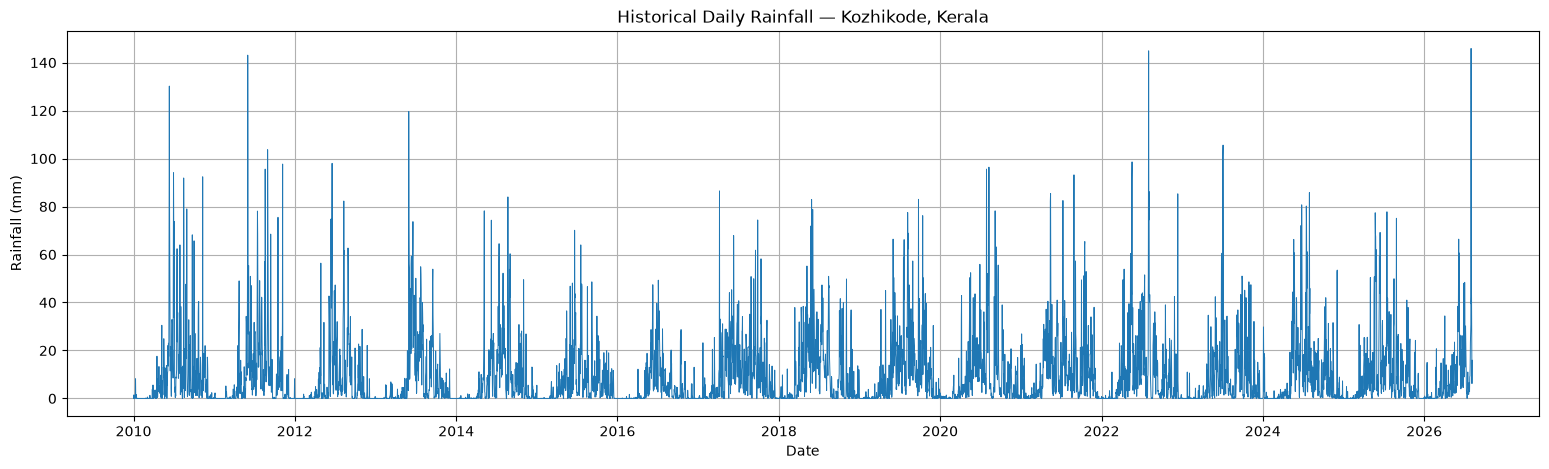

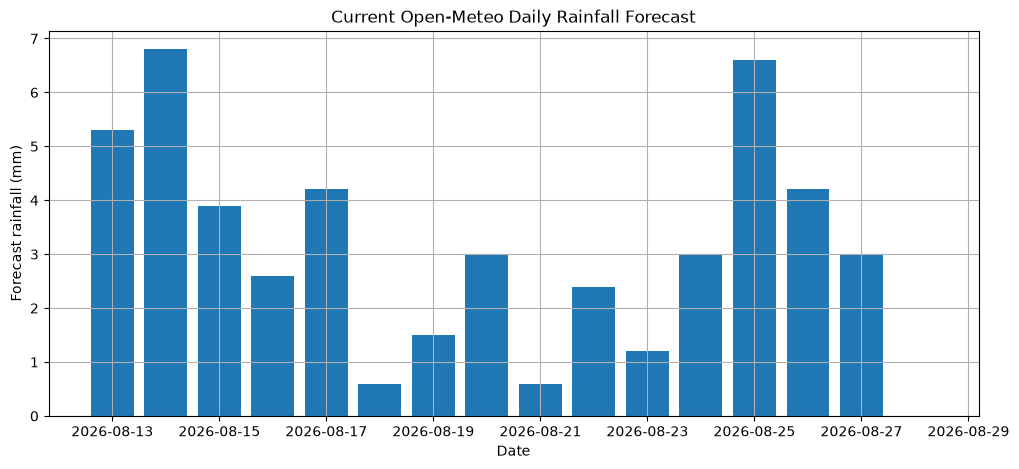

In [30]:
plt.figure(figsize=(19, 5))
plt.plot(historical_weather.index, historical_weather["rain_sum"], linewidth=0.7)
plt.title(f"Historical Daily Rainfall — {location['name']}, {location.get('admin1')}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(future_weather.index, future_weather["rain_sum"])
plt.title("Current Open-Meteo Daily Rainfall Forecast")
plt.xlabel("Date")
plt.ylabel("Forecast rainfall (mm)")
plt.grid(True)
plt.show()

# Part B — Weather-window feature engineering

For each 7-day or 14-day period the model sees more than total rainfall. It also sees the maximum single-day rain, rainy-day count, wet-day count, precipitation hours and consecutive rainy-day streak.

## 7. Feature functions

In [7]:
def longest_true_streak(values):
    best = 0
    current = 0
    for value in values:
        if bool(value):
            current += 1
            best = max(best, current)
        else:
            current = 0
    return best

MODEL_FEATURES = [
    "rain_total_mm",
    "rain_avg_mm",
    "rain_max_day_mm",
    "rainy_days",
    "moderate_rain_days",
    "very_wet_days",
    "precipitation_hours_total",
    "longest_rainy_streak",
    "wet_day_fraction",
    "rain_concentration_ratio"
]

def weather_window_features(window):
    rain = window["rain_sum"].to_numpy(dtype=float)
    precip_hours = window["precipitation_hours"].to_numpy(dtype=float)

    rainy = rain >= RAINY_DAY_MM
    moderate = rain >= MODERATE_RAIN_DAY_MM
    very_wet = rain >= VERY_WET_DAY_MM

    total = float(rain.sum())
    maximum = float(rain.max()) if len(rain) else 0.0

    return {
        "rain_total_mm": total,
        "rain_avg_mm": float(rain.mean()),
        "rain_max_day_mm": maximum,
        "rainy_days": int(rainy.sum()),
        "moderate_rain_days": int(moderate.sum()),
        "very_wet_days": int(very_wet.sum()),
        "precipitation_hours_total": float(precip_hours.sum()),
        "longest_rainy_streak": int(longest_true_streak(rainy)),
        "wet_day_fraction": float(rainy.mean()),
        "rain_concentration_ratio": maximum / total if total > 0 else 0.0
    }

## 8. Build historical sliding windows

In [8]:
def build_historical_windows(weather_df, horizon_days):
    rows = []

    for end_pos in range(horizon_days - 1, len(weather_df)):
        start_pos = end_pos - horizon_days + 1
        window = weather_df.iloc[start_pos:end_pos + 1]

        start_date = window.index.min()
        end_date = window.index.max()
        center_date = start_date + (end_date - start_date) / 2

        rows.append({
            "window_start": start_date,
            "window_end": end_date,
            "center_date": center_date,
            "reference_month": int(center_date.month),
            **weather_window_features(window)
        })

    return pd.DataFrame(rows).set_index("window_end")

historical_windows = {}
for horizon in HORIZONS:
    historical_windows[horizon] = build_historical_windows(historical_weather, horizon)
    print(horizon, "day windows:", len(historical_windows[horizon]))

7 day windows: 6056
14 day windows: 6049


## 9. Inspect the 7-day feature distribution

In [9]:
display(historical_windows[7][MODEL_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
rain_total_mm,6056.0,64.572176,75.172485,0.0,5.300000,37.800000,98.625000,499.400000
rain_avg_mm,6056.0,9.224597,10.738926,0.0,0.757143,5.400000,14.089286,71.342857
rain_max_day_mm,6056.0,21.835733,23.837462,0.0,2.700000,14.900000,32.625000,145.900000
rainy_days,6056.0,5.288804,2.381247,0.0,4.000000,7.000000,7.000000,7.000000
moderate_rain_days,6056.0,1.067536,1.628269,0.0,0.000000,0.000000,2.000000,7.000000
very_wet_days,6056.0,0.187087,0.614581,0.0,0.000000,0.000000,0.000000,6.000000
precipitation_hours_total,6056.0,64.701948,52.369167,0.0,15.000000,56.000000,108.000000,168.000000
longest_rainy_streak,6056.0,5.019815,2.525824,0.0,3.000000,7.000000,7.000000,7.000000
wet_day_fraction,6056.0,0.755543,0.340178,0.0,0.571429,1.000000,1.000000,1.000000
rain_concentration_ratio,6056.0,0.420829,0.239814,0.0,0.276794,0.369513,0.526375,1.000000


# Part C — Seasonally conditioned Isolation Forest

A wet July week should not automatically be called abnormal simply because July is usually wet. For each forecast, the reference set uses the target month and adjacent months.

## 10. Seasonal month helper

In [10]:
def seasonal_months(target_month, radius=1):
    months = []
    for offset in range(-radius, radius + 1):
        month = ((target_month - 1 + offset) % 12) + 1
        months.append(month)
    return sorted(set(months))

print("January reference:", seasonal_months(1, SEASONAL_MONTH_RADIUS))
print("August reference:", seasonal_months(8, SEASONAL_MONTH_RADIUS))
print("December reference:", seasonal_months(12, SEASONAL_MONTH_RADIUS))

January reference: [1, 2, 12]
August reference: [7, 8, 9]
December reference: [1, 11, 12]


## 11. Fit Isolation Forest and convert score to anomaly percentile

In [11]:
def fit_seasonal_iforest(historical_feature_df, target_month):
    months = seasonal_months(target_month, SEASONAL_MONTH_RADIUS)

    reference = historical_feature_df[
        historical_feature_df["reference_month"].isin(months)
    ].copy()

    if len(reference) < 100:
        raise ValueError("Seasonal reference set is too small.")

    X = reference[MODEL_FEATURES].astype(float)

    model = IsolationForest(
        n_estimators=IFOREST_TREES,
        max_samples=IFOREST_MAX_SAMPLES,
        contamination="auto",
        random_state=RANDOM_STATE
    )
    model.fit(X)

    reference_scores = model.score_samples(X)
    return model, reference, reference_scores


def anomaly_percentile(reference_scores, new_score):
    # Isolation Forest: lower raw score = more abnormal.
    # A very low new score means most historical windows scored higher.
    return float(np.mean(reference_scores >= new_score) * 100)

## 12. Historical percentile helpers

In [12]:
def empirical_percentile(historical_values, new_value):
    values = np.asarray(historical_values, dtype=float)
    return float(np.mean(values <= float(new_value)) * 100)


def percentile_table(values):
    values = np.asarray(values, dtype=float)
    return pd.Series({
        "P50": np.quantile(values, 0.50),
        "P75": np.quantile(values, 0.75),
        "P90": np.quantile(values, 0.90),
        "P95": np.quantile(values, 0.95),
        "P99": np.quantile(values, 0.99)
    })


def risk_label(anomaly_pct):
    if anomaly_pct >= 97.5:
        return "EXTREME"
    if anomaly_pct >= 90:
        return "HIGH"
    if anomaly_pct >= 75:
        return "MEDIUM"
    return "LOW"

# Part D — Score the future 7-day and 14-day forecasts

The Isolation Forest anomaly percentile is the main model signal. Historical rainfall percentile is shown beside it so the result can be explained to management.

## 13. Convert future forecast into a model feature vector

In [13]:
def future_window_features(forecast_df, horizon_days):
    if len(forecast_df) < horizon_days:
        raise ValueError(
            f"Only {len(forecast_df)} forecast days available; {horizon_days} required."
        )

    window = forecast_df.iloc[:horizon_days].copy()
    start_date = window.index.min()
    end_date = window.index.max()
    center_date = start_date + (end_date - start_date) / 2

    feature_df = pd.DataFrame(
        [weather_window_features(window)],
        index=[end_date]
    )

    return feature_df, int(center_date.month), start_date, end_date

## 14. Score one forecast horizon

In [14]:
def score_future_horizon(historical_feature_df, forecast_df, horizon_days):
    future_features, target_month, start_date, end_date = future_window_features(
        forecast_df,
        horizon_days
    )

    model, reference, reference_scores = fit_seasonal_iforest(
        historical_feature_df,
        target_month
    )

    future_score = float(
        model.score_samples(future_features[MODEL_FEATURES].astype(float))[0]
    )

    iforest_pct = anomaly_percentile(reference_scores, future_score)

    rain_pct = empirical_percentile(
        reference["rain_total_mm"],
        future_features.iloc[0]["rain_total_mm"]
    )

    max_day_pct = empirical_percentile(
        reference["rain_max_day_mm"],
        future_features.iloc[0]["rain_max_day_mm"]
    )

    return {
        "horizon_days": horizon_days,
        "forecast_start": start_date,
        "forecast_end": end_date,
        "seasonal_reference_months": ",".join(
            str(x) for x in seasonal_months(target_month, SEASONAL_MONTH_RADIUS)
        ),
        "reference_windows": len(reference),
        "forecast_rain_total_mm": float(future_features.iloc[0]["rain_total_mm"]),
        "forecast_max_daily_rain_mm": float(future_features.iloc[0]["rain_max_day_mm"]),
        "forecast_rainy_days": int(future_features.iloc[0]["rainy_days"]),
        "forecast_very_wet_days": int(future_features.iloc[0]["very_wet_days"]),
        "iforest_raw_score": future_score,
        "iforest_anomaly_percentile": iforest_pct,
        "rain_total_percentile": rain_pct,
        "max_daily_rain_percentile": max_day_pct,
        "weather_risk": risk_label(iforest_pct)
    }

## 15. Run Pipeline 2 on the live forecast

In [15]:
future_results = []
for horizon in HORIZONS:
    future_results.append(
        score_future_horizon(
            historical_windows[horizon],
            future_weather,
            horizon
        )
    )

future_risk_table = pd.DataFrame(future_results)
future_risk_table

,horizon_days,forecast_start,forecast_end,seasonal_reference_months,reference_windows,forecast_rain_total_mm,forecast_max_daily_rain_mm,forecast_rainy_days,forecast_very_wet_days,iforest_raw_score,iforest_anomaly_percentile,rain_total_percentile,max_daily_rain_percentile,weather_risk
0,7,2026-08-13,2026-08-19,"7,8,9",1506,24.9,6.8,7,0,-0.413736,49.070385,14.143426,11.487384,LOW
1,14,2026-08-13,2026-08-26,"7,8,9",1502,45.9,6.8,14,0,-0.475238,72.436751,8.655126,4.460719,LOW


## 16. Management-friendly warning output

In [16]:
for _, row in future_risk_table.iterrows():
    print("=" * 72)
    print(f"{int(row['horizon_days'])}-DAY WEATHER-PRESSURE WARNING")
    print("=" * 72)
    print("Forecast period:", row["forecast_start"], "to", row["forecast_end"])
    print(f"Forecast rainfall: {row['forecast_rain_total_mm']:.1f} mm")
    print(f"Max daily rainfall: {row['forecast_max_daily_rain_mm']:.1f} mm")
    print(f"Rainy days: {int(row['forecast_rainy_days'])}")
    print(f"Isolation Forest anomaly percentile: {row['iforest_anomaly_percentile']:.1f}")
    print(f"Historical rainfall percentile: {row['rain_total_percentile']:.1f}")
    print("WEATHER RISK:", row["weather_risk"])
    print()

    if row["weather_risk"] in ["HIGH", "EXTREME"]:
        print(
            "Operational interpretation: unusually severe weather is forecast. "
            "Retailer stock-depletion pressure may increase. Consider maintaining "
            "production capacity, workforce availability and raw-material readiness."
        )
    else:
        print(
            "Operational interpretation: no major weather-anomaly signal at this horizon."
        )
    print()

7-DAY WEATHER-PRESSURE WARNING
Forecast period: 2026-08-13 00:00:00 to 2026-08-19 00:00:00
Forecast rainfall: 24.9 mm
Max daily rainfall: 6.8 mm
Rainy days: 7
Isolation Forest anomaly percentile: 49.1
Historical rainfall percentile: 14.1
WEATHER RISK: LOW

Operational interpretation: no major weather-anomaly signal at this horizon.

14-DAY WEATHER-PRESSURE WARNING
Forecast period: 2026-08-13 00:00:00 to 2026-08-26 00:00:00
Forecast rainfall: 45.9 mm
Max daily rainfall: 6.8 mm
Rainy days: 14
Isolation Forest anomaly percentile: 72.4
Historical rainfall percentile: 8.7
WEATHER RISK: LOW

Operational interpretation: no major weather-anomaly signal at this horizon.



# Part E — Explain the result with historical percentiles

This section makes the Machine Learning result transparent by showing where forecast rainfall sits relative to historically similar months.

## 17. Seasonal P50 / P75 / P90 / P95 / P99

In [17]:
percentile_rows = []

for horizon in HORIZONS:
    future_features, target_month, start_date, end_date = future_window_features(
        future_weather,
        horizon
    )

    months = seasonal_months(target_month, SEASONAL_MONTH_RADIUS)
    reference = historical_windows[horizon][
        historical_windows[horizon]["reference_month"].isin(months)
    ]

    p = percentile_table(reference["rain_total_mm"])

    percentile_rows.append({
        "horizon_days": horizon,
        "reference_months": ",".join(map(str, months)),
        **p.to_dict(),
        "forecast_rain_mm": float(future_features.iloc[0]["rain_total_mm"])
    })

seasonal_percentiles = pd.DataFrame(percentile_rows)
seasonal_percentiles

,horizon_days,reference_months,P50,P75,P90,P95,P99,forecast_rain_mm
0,7,"7,8,9",89.60,153.800,218.0,263.700,349.200,24.9
1,14,"7,8,9",199.75,302.075,378.7,419.895,531.788,45.9


## 18. Plot forecast rainfall against historical seasonal windows

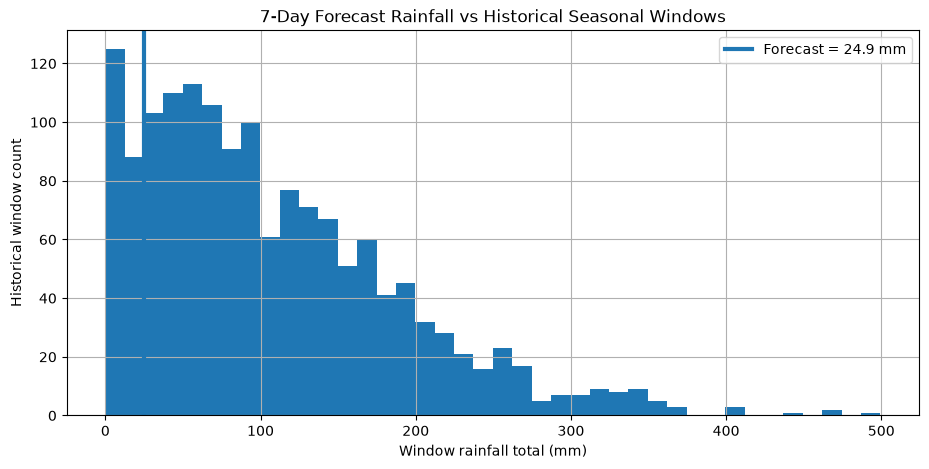

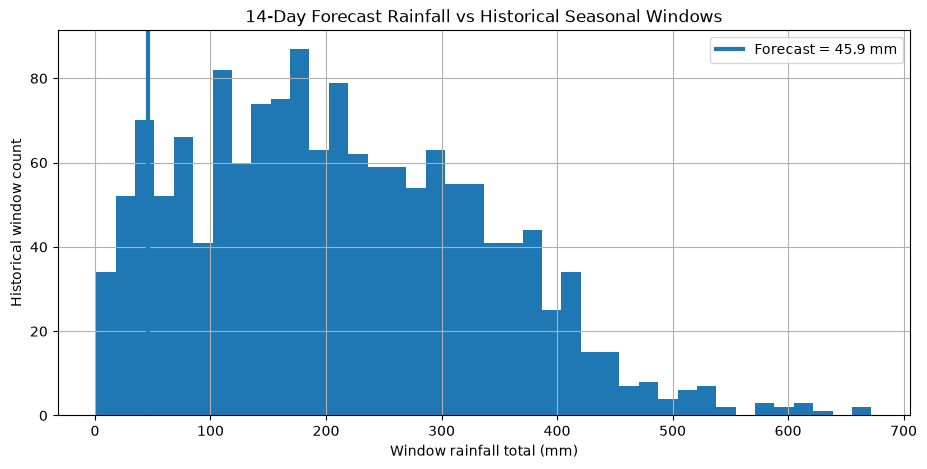

In [18]:
for horizon in HORIZONS:
    future_features, target_month, _, _ = future_window_features(future_weather, horizon)
    months = seasonal_months(target_month, SEASONAL_MONTH_RADIUS)

    reference = historical_windows[horizon][
        historical_windows[horizon]["reference_month"].isin(months)
    ]

    forecast_value = float(future_features.iloc[0]["rain_total_mm"])

    plt.figure(figsize=(11, 5))
    plt.hist(reference["rain_total_mm"], bins=40)
    plt.axvline(
        forecast_value,
        linewidth=3,
        label=f"Forecast = {forecast_value:.1f} mm"
    )
    plt.title(f"{horizon}-Day Forecast Rainfall vs Historical Seasonal Windows")
    plt.xlabel("Window rainfall total (mm)")
    plt.ylabel("Historical window count")
    plt.legend()
    plt.grid(True)
    plt.show()

# Part F — Historical anomaly inspection

Because this is unsupervised learning and there are no reliable surge labels yet, accuracy, precision, recall and F1 score are not appropriate model-selection metrics at this stage.

Instead, inspect whether the model's most abnormal historical windows genuinely look like extreme weather events.

## 19. Score historical windows seasonally

In [19]:
def score_historical_windows_seasonally(feature_df):
    result = feature_df.copy()
    result["iforest_raw_score"] = np.nan
    result["anomaly_percentile"] = np.nan

    for month in range(1, 13):
        months = seasonal_months(month, SEASONAL_MONTH_RADIUS)
        reference = feature_df[
            feature_df["reference_month"].isin(months)
        ]
        target_mask = feature_df["reference_month"] == month
        target = feature_df.loc[target_mask]

        if len(reference) < 100 or len(target) == 0:
            continue

        model = IsolationForest(
            n_estimators=IFOREST_TREES,
            max_samples=IFOREST_MAX_SAMPLES,
            contamination="auto",
            random_state=RANDOM_STATE
        )
        model.fit(reference[MODEL_FEATURES])

        ref_scores = model.score_samples(reference[MODEL_FEATURES])
        target_scores = model.score_samples(target[MODEL_FEATURES])
        target_percentiles = [
            anomaly_percentile(ref_scores, score)
            for score in target_scores
        ]

        result.loc[target.index, "iforest_raw_score"] = target_scores
        result.loc[target.index, "anomaly_percentile"] = target_percentiles

    return result

historical_7d_scored = score_historical_windows_seasonally(
    historical_windows[7]
)

## 20. Top historical 7-day weather anomalies

In [20]:
top_historical_anomalies = (
    historical_7d_scored
    .sort_values("anomaly_percentile", ascending=False)
    .head(25)
)

display(
    top_historical_anomalies[
        [
            "window_start",
            "center_date",
            "reference_month",
            "rain_total_mm",
            "rain_max_day_mm",
            "rainy_days",
            "very_wet_days",
            "precipitation_hours_total",
            "anomaly_percentile"
        ]
    ]
)

,window_start,center_date,reference_month,rain_total_mm,rain_max_day_mm,rainy_days,very_wet_days,precipitation_hours_total,anomaly_percentile
window_end,,,,,,,,,
2025-05-30,2025-05-24,2025-05-27,5,440.8,77.4,7,6,167.0,100.000000
2018-09-15,2018-09-09,2018-09-12,9,0.0,0.0,0,0,0.0,99.728814
2018-09-16,2018-09-10,2018-09-13,9,0.0,0.0,0,0,0.0,99.728814
2012-09-26,2012-09-20,2012-09-23,9,0.0,0.0,0,0,0.0,99.728814
2011-11-12,2011-11-06,2011-11-09,11,130.6,97.7,4,1,35.0,99.592391
2022-08-07,2022-08-01,2022-08-04,8,499.4,144.9,7,4,168.0,99.535193
2022-12-18,2022-12-12,2022-12-15,12,96.0,85.3,4,1,46.0,99.533333
2011-11-13,2011-11-07,2011-11-10,11,99.4,97.7,4,1,26.0,99.524457
2019-10-20,2019-10-14,2019-10-17,10,262.1,76.2,7,2,127.0,99.519231


## 21. Plot historical anomaly percentile

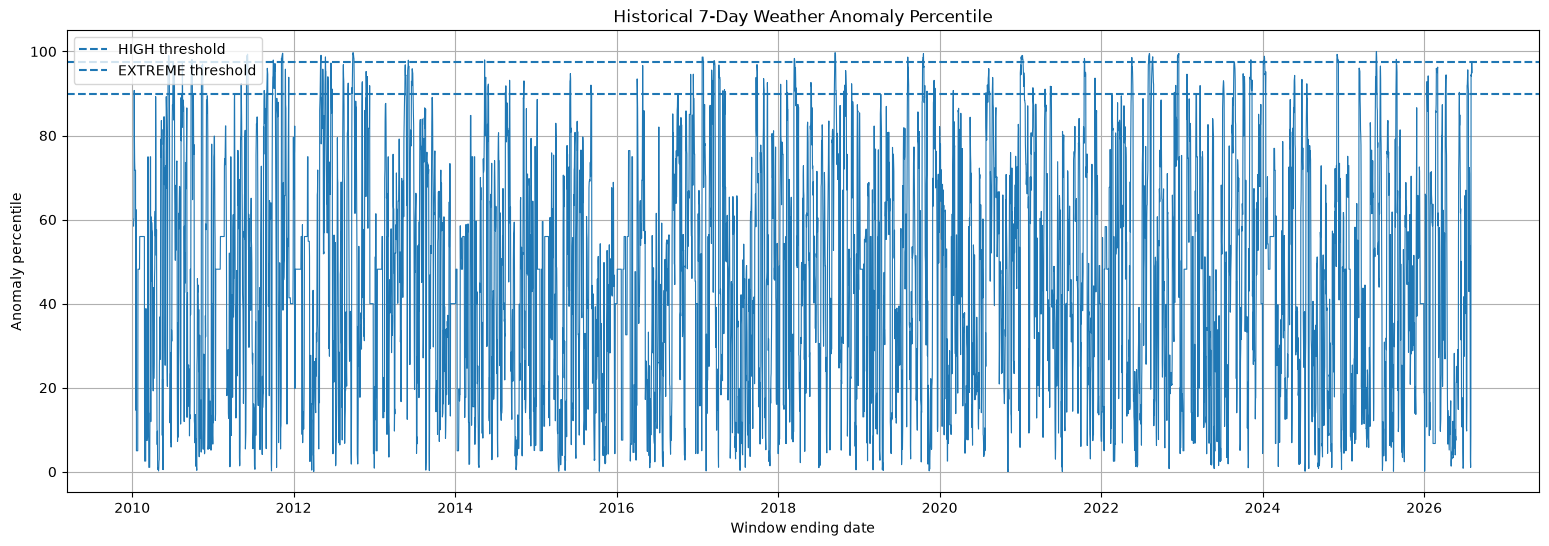

In [21]:
plt.figure(figsize=(19, 6))
plt.plot(
    historical_7d_scored.index,
    historical_7d_scored["anomaly_percentile"],
    linewidth=0.8
)
plt.axhline(90, linestyle="--", label="HIGH threshold")
plt.axhline(97.5, linestyle="--", label="EXTREME threshold")
plt.title("Historical 7-Day Weather Anomaly Percentile")
plt.xlabel("Window ending date")
plt.ylabel("Anomaly percentile")
plt.legend()
plt.grid(True)
plt.show()

# Part G — Optional Johns sales association experiment

This section is exploratory only. It does **not** train Isolation Forest on sales.

It asks whether high weather anomaly scores tend to be followed by positive Johns weekly sales deviations in the same week or 1–2 weeks later.

The sales-surge variable here is only a proxy because the real emergency-reorder labels do not yet exist.

## 22. Load Johns weekly sales if available

In [22]:
def load_weekly_sales(path):
    df = pd.read_csv(path)

    date_col = next(
        (c for c in ["week_ending", "date", "week"] if c in df.columns),
        None
    )
    sales_col = next(
        (c for c in ["weekly_sales_total", "weekly_sales", "sales"] if c in df.columns),
        None
    )

    if date_col is None or sales_col is None:
        raise KeyError(f"Unsupported weekly CSV columns: {list(df.columns)}")

    out = df[[date_col, sales_col]].rename(
        columns={date_col: "week_ending", sales_col: "sales"}
    )
    out["week_ending"] = pd.to_datetime(out["week_ending"])
    out["sales"] = pd.to_numeric(out["sales"], errors="coerce")
    return out.dropna().set_index("week_ending").sort_index()

if WEEKLY_SALES_CSV.exists():
    johns_weekly = load_weekly_sales(WEEKLY_SALES_CSV)
    print("Weekly sales loaded:", len(johns_weekly))
    display(johns_weekly.head())
else:
    johns_weekly = None
    print("Optional weekly sales file not found.")
    print("Set WEEKLY_SALES_CSV if you want to run this section.")

Optional weekly sales file not found.
Set WEEKLY_SALES_CSV if you want to run this section.


## 23. Build Sunday-ending 7-day weather windows

In [23]:
def build_sunday_weather_windows(weather_df):
    rows = []
    sundays = pd.date_range(weather_df.index.min(), weather_df.index.max(), freq="W-SUN")

    for sunday in sundays:
        start = sunday - pd.Timedelta(days=6)
        window = weather_df.loc[start:sunday]
        if len(window) != 7:
            continue

        rows.append({
            "week_ending": sunday,
            "reference_month": int(sunday.month),
            **weather_window_features(window)
        })

    return pd.DataFrame(rows).set_index("week_ending")

sunday_weather = build_sunday_weather_windows(historical_weather)
sunday_weather_scored = score_historical_windows_seasonally(sunday_weather)
display(sunday_weather_scored.tail())

,reference_month,rain_total_mm,rain_avg_mm,rain_max_day_mm,rainy_days,moderate_rain_days,very_wet_days,precipitation_hours_total,longest_rainy_streak,wet_day_fraction,rain_concentration_ratio,iforest_raw_score,anomaly_percentile
week_ending,,,,,,,,,,,,,
2026-07-05,7,182.0,26.000000,48.4,7,4,0,159.0,7,1.000000,0.265934,-0.387786,31.506849
2026-07-12,7,112.5,16.071429,30.2,7,3,0,142.0,7,1.000000,0.268444,-0.374500,7.305936
2026-07-19,7,34.9,4.985714,11.0,6,0,0,87.0,5,0.857143,0.315186,-0.545967,91.780822
2026-07-26,7,35.3,5.042857,9.0,7,0,0,85.0,7,1.000000,0.254958,-0.415829,59.817352
2026-08-02,8,291.0,41.571429,145.9,7,5,1,156.0,7,1.000000,0.501375,-0.598369,96.279070


## 24. Create a simple positive sales-surge proxy

In [24]:
if johns_weekly is not None:
    sales_eval = johns_weekly.copy()

    sales_eval["baseline_4w_median"] = (
        sales_eval["sales"]
        .shift(1)
        .rolling(4)
        .median()
    )

    sales_eval["positive_surge_amount"] = (
        sales_eval["sales"] - sales_eval["baseline_4w_median"]
    ).clip(lower=0)

    sales_eval["sales_to_baseline_ratio"] = (
        sales_eval["sales"]
        / sales_eval["baseline_4w_median"].replace(0, np.nan)
    )

    combined = sales_eval.join(
        sunday_weather_scored[
            ["rain_total_mm", "rain_max_day_mm", "anomaly_percentile"]
        ],
        how="left"
    )

    display(combined.tail(15))

## 25. Weather anomaly vs same-week / next-week / two-week-later sales surge

In [25]:
if johns_weekly is not None:
    lag_rows = []

    for lag in [0, 1, 2]:
        future_surge = combined["positive_surge_amount"].shift(-lag)

        valid = pd.DataFrame({
            "weather_anomaly": combined["anomaly_percentile"],
            "future_surge": future_surge
        }).dropna()

        lag_rows.append({
            "weather_leads_sales_by_weeks": lag,
            "correlation": valid["weather_anomaly"].corr(valid["future_surge"]),
            "observations": len(valid)
        })

    lag_analysis = pd.DataFrame(lag_rows)
    display(lag_analysis)

## 26. Inspect Johns weeks with the highest historical weather anomaly

In [26]:
if johns_weekly is not None:
    display(
        combined
        .sort_values("anomaly_percentile", ascending=False)
        [
            [
                "sales",
                "baseline_4w_median",
                "positive_surge_amount",
                "sales_to_baseline_ratio",
                "rain_total_mm",
                "rain_max_day_mm",
                "anomaly_percentile"
            ]
        ]
        .head(20)
    )

# Part H — What-if simulation for a demo

If the live forecast happens to be normal on demo day, simulate a stronger-rain scenario and see how the anomaly model reacts. This is clearly labeled as a simulation, not a real forecast.

## 27. Simulate stronger rainfall

In [27]:
SCENARIO_RAIN_MULTIPLIER = 1.75

scenario_weather = future_weather.copy()
scenario_weather["rain_sum"] *= SCENARIO_RAIN_MULTIPLIER
scenario_weather["precipitation_sum"] *= SCENARIO_RAIN_MULTIPLIER

scenario_results = []
for horizon in HORIZONS:
    scenario_results.append(
        score_future_horizon(
            historical_windows[horizon],
            scenario_weather,
            horizon
        )
    )

scenario_risk_table = pd.DataFrame(scenario_results)
scenario_risk_table["scenario_rain_multiplier"] = SCENARIO_RAIN_MULTIPLIER
scenario_risk_table

,horizon_days,forecast_start,forecast_end,seasonal_reference_months,reference_windows,forecast_rain_total_mm,forecast_max_daily_rain_mm,forecast_rainy_days,forecast_very_wet_days,iforest_raw_score,iforest_anomaly_percentile,rain_total_percentile,max_daily_rain_percentile,weather_risk,scenario_rain_multiplier
0,7,2026-08-13,2026-08-19,"7,8,9",1506,43.575,11.9,7,0,-0.390988,23.439575,25.166003,18.326693,LOW,1.75
1,14,2026-08-13,2026-08-26,"7,8,9",1502,80.325,11.9,14,0,-0.444565,61.651132,17.376831,7.989348,LOW,1.75


## 28. Compare live forecast and simulated scenario

In [28]:
real_compare = future_risk_table[
    [
        "horizon_days",
        "forecast_rain_total_mm",
        "iforest_anomaly_percentile",
        "rain_total_percentile",
        "weather_risk"
    ]
].copy()
real_compare["type"] = "Live forecast"

scenario_compare = scenario_risk_table[
    [
        "horizon_days",
        "forecast_rain_total_mm",
        "iforest_anomaly_percentile",
        "rain_total_percentile",
        "weather_risk"
    ]
].copy()
scenario_compare["type"] = f"What-if x{SCENARIO_RAIN_MULTIPLIER}"

comparison_demo = pd.concat([real_compare, scenario_compare], ignore_index=True)
comparison_demo

,horizon_days,forecast_rain_total_mm,iforest_anomaly_percentile,rain_total_percentile,weather_risk,type
0,7,24.900,49.070385,14.143426,LOW,Live forecast
1,14,45.900,72.436751,8.655126,LOW,Live forecast
2,7,43.575,23.439575,25.166003,LOW,What-if x1.75
3,14,80.325,61.651132,17.376831,LOW,What-if x1.75


# Part I — Exports

## 29. Save outputs

In [29]:
future_risk_table.to_csv(
    "johns_pipeline2_live_weather_risk.csv",
    index=False
)

seasonal_percentiles.to_csv(
    "johns_pipeline2_seasonal_rain_percentiles.csv",
    index=False
)

scenario_risk_table.to_csv(
    "johns_pipeline2_what_if_weather_risk.csv",
    index=False
)

top_historical_anomalies.to_csv(
    "johns_pipeline2_top_historical_weather_anomalies.csv"
)

if johns_weekly is not None:
    combined.to_csv(
        "johns_pipeline2_weather_sales_exploration.csv"
    )
    lag_analysis.to_csv(
        "johns_pipeline2_weather_sales_lag_analysis.csv",
        index=False
    )

print("Exports complete.")

Exports complete.


# Final interpretation guide

## Main table

Use:

```python
future_risk_table
```

Example:

```text
7-day Isolation Forest anomaly percentile = 98.4
Historical rainfall percentile            = 96.9
Weather risk                              = EXTREME
```

Interpretation:

> The coming weather window looks more abnormal than approximately 98% of seasonally comparable historical weather windows.

Do **not** interpret it as:

> There is a 98% probability of a Johns sales surge.

## Operational demo logic

```text
Pipeline 1
Weekly ARIMAX + Business Calendar
        ↓
Normal expected weekly sales

Pipeline 2
10+ years historical weather
        ↓
7-day / 14-day weather features
        ↓
Seasonally conditioned Isolation Forest
        +
Historical P75/P90/P95/P99
        ↓
Live future rainfall forecast
        ↓
LOW / MEDIUM / HIGH / EXTREME
weather-driven replenishment warning
```

## Why 7-day and 14-day horizons?

- **7-day**: immediate production/workforce readiness.
- **14-day**: earlier supplier/raw-material planning.

## Current limitation

Isolation Forest detects unusual weather, not retailer stock depletion directly.

The real chain is:

```text
unusual rain
    ↓
consumer umbrella demand increases
    ↓
retailer stock drops
    ↓
emergency Johns reorder
```

## Future upgrade

When more Johns data is available:

1. create a real target such as `emergency_reorder_next_14_days`,
2. add retailer order history and stock proxies,
3. add retailer-specific locations,
4. keep the Isolation Forest anomaly score as one feature,
5. train a supervised classifier such as Extreme Gradient Boosting or Light Gradient-Boosting Machine,
6. evaluate using precision, recall, F1 score and confusion matrix,
7. optionally train a second regression model for expected extra quantity.

# Official references

- Open-Meteo Geocoding API: https://open-meteo.com/en/docs/geocoding-api
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api
- Open-Meteo Forecast API: https://open-meteo.com/en/docs
- Scikit-learn Isolation Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html